In [15]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nanosurrogate.env import setup_gpu_env
setup_gpu_env()

from tensorflow.keras.models import load_model
from nanosurrogate.models import HurdleSurrogate
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.style.use("seaborn-v0_8-poster")

# Adjust path
MODEL_DIR = Path("../models/hurdle_baseline")
if not MODEL_DIR.exists():
    MODEL_DIR = Path("models/hurdle_baseline")

# 1. Load model
clf = load_model(MODEL_DIR / "classifier_model.keras")
reg = load_model(MODEL_DIR / "regressor_model.keras")

# 2. load scaler & parameter
with open(MODEL_DIR / "scalers.pkl", "rb") as f:
    scaler_data = pickle.load(f)

x_scaler = scaler_data["x_scaler"]
y_scaler = scaler_data["y_scaler"]
scale_factor = scaler_data["scale_factor"]
blockade_threshold = scaler_data["blockade_threshold"]

# 3. train history & untoched test set
with open(MODEL_DIR / "training_history.pkl", "rb") as f:
    history = pickle.load(f)

test_data = np.load(MODEL_DIR / "test_data.npz")
X_test_raw    = test_data["X_test_raw"]
X_test_scaled = test_data["X_test_scaled"]
y_test_class  = test_data["y_test_class"].flatten()
y_test_raw    = test_data["y_test_raw"].flatten()
y_test_trans  = test_data["y_test_trans"].flatten()
weights_test  = test_data["weights_test"].flatten()

# 4. Init Combined Hurdle-Modell
surrogate = HurdleSurrogate(classifier=clf, regressor=reg, x_scaler=x_scaler, y_scaler=y_scaler, scale_factor=scale_factor)

print(f"Models loaded from: {MODEL_DIR.resolve()}")
print(f"Test Size: {len(X_test_raw)} Samples ({np.mean(y_test_class == 0)*100:.1f}% blocked)")

⚠️ Warning: 'nvidia' directory not found in site-packages. GPU might not be detected if relying on pip-installed CUDA.
⚠️ No GPU found by TensorFlow. Falling back to CPU.
Models loaded from: /home/j/j_mens07/phd/nanosurrogate/models/hurdle_baseline
Test Size: 611 Samples (0.3% blocked)


/home/j/j_mens07/phd/nanosurrogate/venv/lib64/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Best Val-Loss Regressor: 0.087741 (in epoch 500)


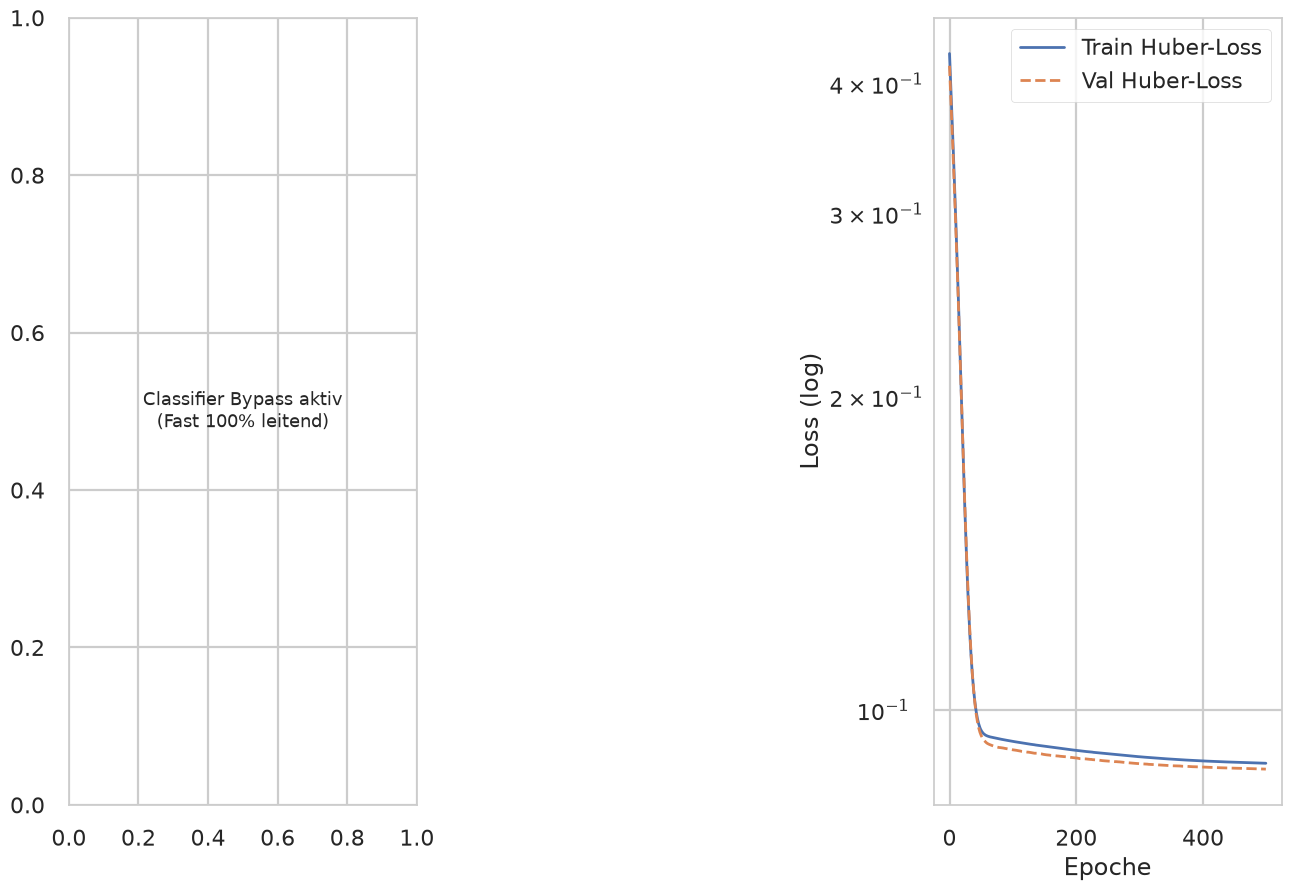

In [9]:
fig, axes = plt.subplots(1, 3, layout='constrained')

hist_clf = history["classifier"]
hist_reg = history["regressor"]

# --- Plot 1: Classifier Loss ---
if "bypass" not in hist_clf:
    axes[0].plot(hist_clf["loss"], label="Train Loss", lw=2)
    axes[0].plot(hist_clf["val_loss"], label="Val Loss", lw=2, linestyle="--")
    axes[0].set_title("1. Classifier: Binary Crossentropy")
    axes[0].set_xlabel("Epoche")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    # --- Plot 2: Classifier AUC ---
    axes[1].plot(hist_clf["auc"], label="Train AUC", lw=2, color="darkgreen")
    axes[1].plot(hist_clf["val_auc"], label="Val AUC", lw=2, color="limegreen", linestyle="--")
    axes[1].set_title("2. Classifier: ROC-AUC (Trennschärfe)")
    axes[1].set_xlabel("Epoche")
    axes[1].set_ylabel("AUC (1.0 = Perfekt)")
    axes[1].legend()
else:
    axes[0].text(0.5, 0.5, "Classifier Bypass aktiv\n(Fast 100% leitend)", ha="center", va="center")
    axes[1].axis("off")

# --- Plot 3: Regressor Loss (Log-Skala für feine Unterschiede) ---
axes[2].plot(hist_reg["loss"], label="Train Huber-Loss", lw=2)
axes[2].plot(hist_reg["val_loss"], label="Val Huber-Loss", lw=2, linestyle="--")
axes[2].set_yscale("log")
axes[2].set_xlabel("Epoche")
axes[2].set_ylabel("Loss (log)")
axes[2].legend()

print(f"Best Val-Loss Regressor: {min(hist_reg['val_loss']):.6f} (in epoch {np.argmin(hist_reg['val_loss'])+1})")

               precision    recall  f1-score   support

Blockiert (0)     0.0000    0.0000    0.0000         2
  Leitend (1)     0.9967    1.0000    0.9984       609

     accuracy                         0.9967       611
    macro avg     0.4984    0.5000    0.4992       611
 weighted avg     0.9935    0.9967    0.9951       611

ROC-AUC Score: 0.5000


/home/j/j_mens07/phd/nanosurrogate/venv/lib64/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/j/j_mens07/phd/nanosurrogate/venv/lib64/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/j/j_mens07/phd/nanosurrogate/venv/lib64/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

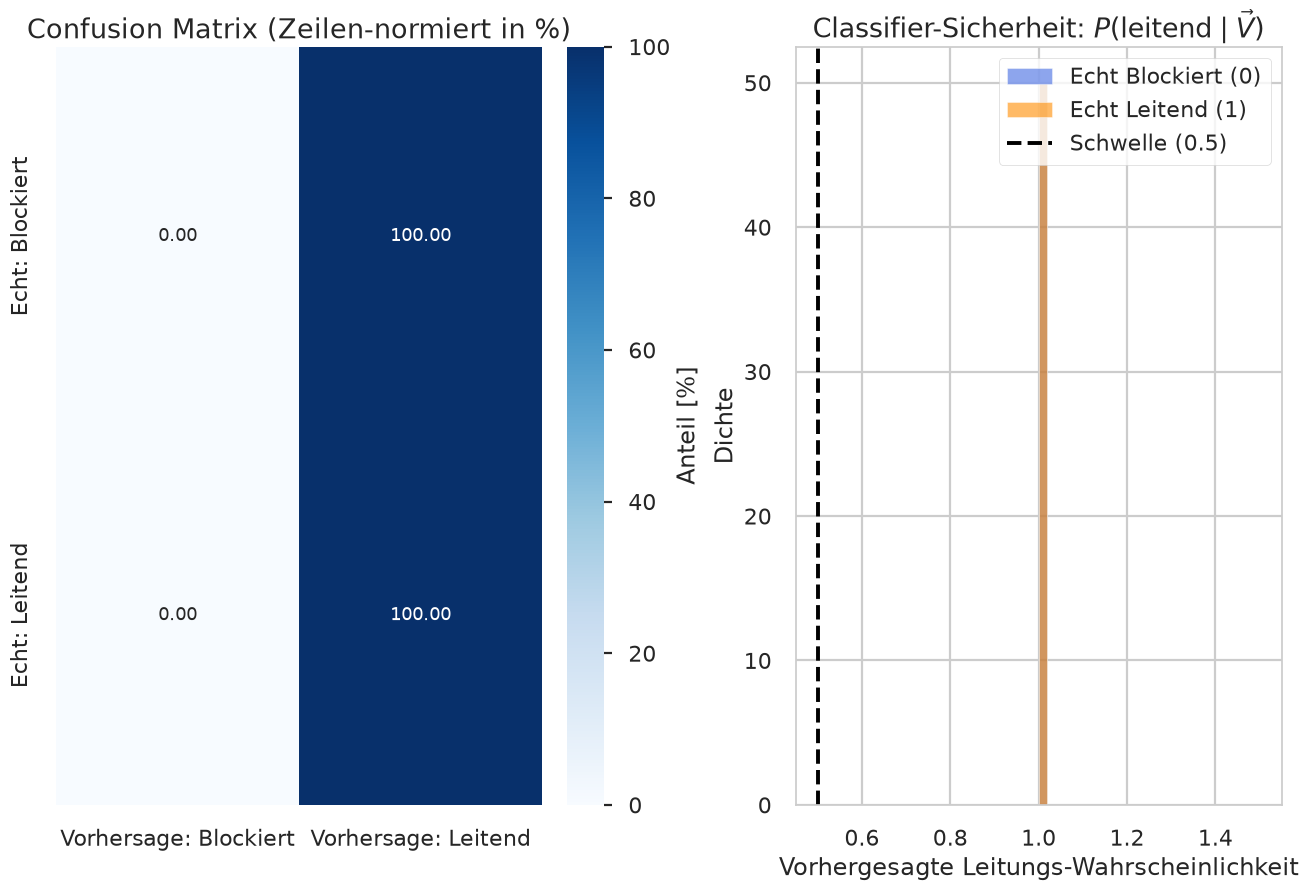

In [14]:
prob_cond = clf.predict(X_test_scaled, batch_size=4096, verbose=0).flatten()
pred_class = (prob_cond >= 0.5).astype(int)

print(classification_report(y_test_class, pred_class, target_names=["Blockiert (0)", "Leitend (1)"], digits=4))
if len(np.unique(y_test_class)) > 1:
    print(f"ROC-AUC Score: {roc_auc_score(y_test_class, prob_cond):.4f}")

fig, axes = plt.subplots(1, 2, layout='constrained')

# --- Plot 1: Confusion Matrix ---
cm = confusion_matrix(y_test_class, pred_class, normalize="true") * 100
sns.heatmap(
    cm, annot=True, fmt=".2f", cmap="Blues", ax=axes[0],
    xticklabels=["Vorhersage: Blockiert", "Vorhersage: Leitend"],
    yticklabels=["Echt: Blockiert", "Echt: Leitend"],
    cbar_kws={"label": "Anteil [%]"}
)
axes[0].set_title("Confusion Matrix (Zeilen-normiert in %)")

# --- Plot 2: Entscheidungs-Sicherheit (Histogramm der Wahrscheinlichkeiten) ---
axes[1].hist(prob_cond[y_test_class == 0], bins=50, alpha=0.6, label="Echt Blockiert (0)", color="royalblue", density=True)
axes[1].hist(prob_cond[y_test_class == 1], bins=50, alpha=0.6, label="Echt Leitend (1)", color="darkorange", density=True)
axes[1].axvline(0.5, color="black", linestyle="--", label="Schwelle (0.5)")
axes[1].set_title("Classifier-Sicherheit: $P(\mathrm{leitend} \mid \\vec{V})$")
axes[1].set_xlabel("Vorhergesagte Leitungs-Wahrscheinlichkeit")
axes[1].set_ylabel("Dichte")
axes[1].legend()

=== REGRESSOR METRIKEN (Nur echt leitende Punkte) ===
R² (im arcsinh-Raum):        0.6343
MAE (im arcsinh-Raum):       10.1741
Medianer Relativer Fehler:   100.00 %

=== END-TO-END HURDLE METRIKEN (Alle Testpunkte inkl. Blockade) ===
R² Gesamt (Hard Gating):     0.6342
R² Gesamt (Soft Gating):     0.6342


Text(0, 0.5, 'Fehler ($\\hat{y}_{\\mathrm{trans}} - y_{\\mathrm{trans}}$)')

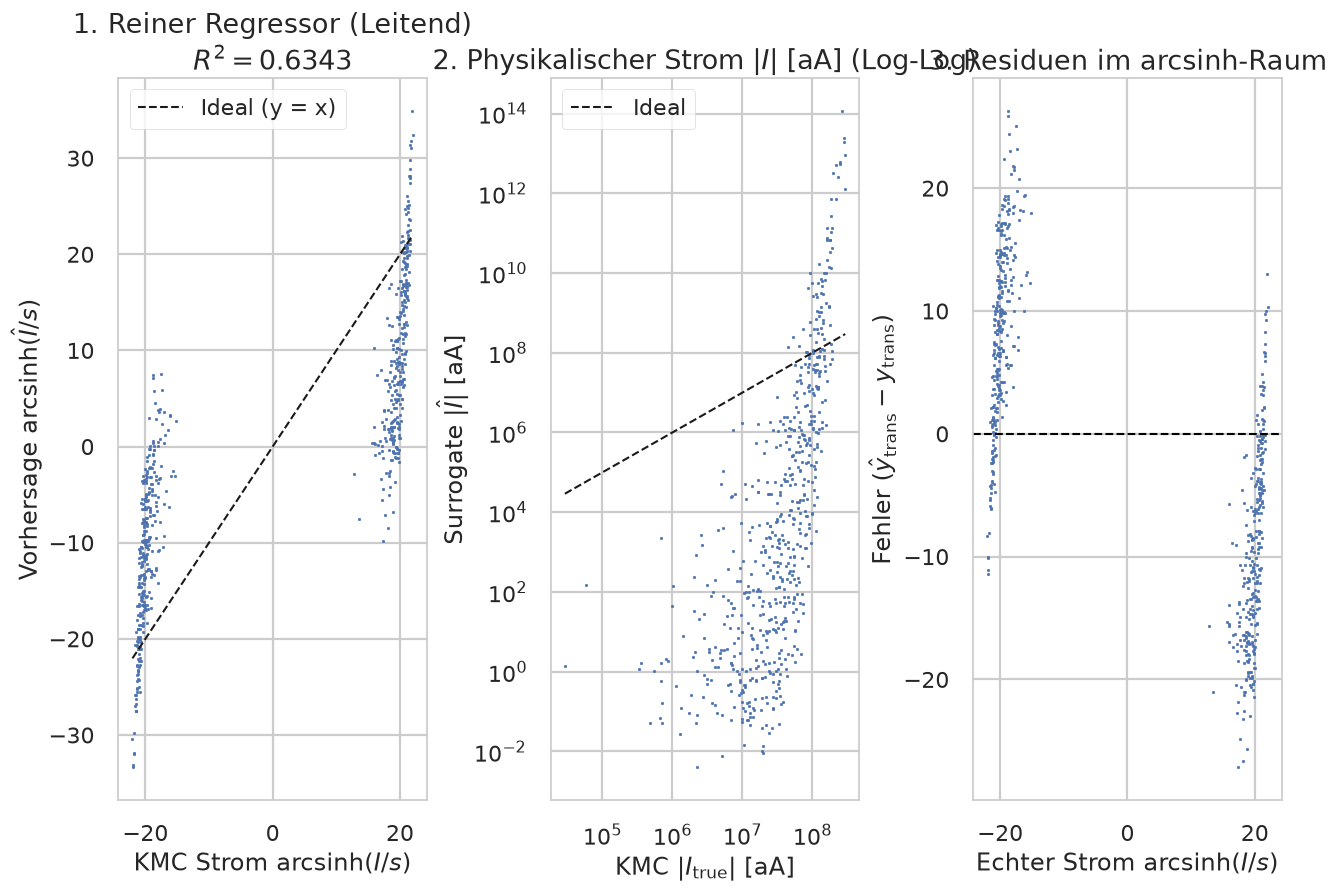

In [20]:
# 1. End-to-End Vorhersage (Hard Gating vs. Soft Gating)
I_pred_hard = surrogate.predict(X_test_raw, prob_threshold=0.5, soft_gating=False).flatten()
I_pred_soft = surrogate.predict(X_test_raw, soft_gating=True).flatten()

# Transformation in den arcsinh-Raum für faire Bewertung über alle Größenordnungen
y_pred_trans_hard = np.arcsinh(I_pred_hard / scale_factor)
y_pred_trans_soft = np.arcsinh(I_pred_soft / scale_factor)

# 2. Reiner Regressor-Test (NUR auf den wirklich leitenden Punkten: y_test_class == 1)
cond_mask = (y_test_class == 1.0)
y_reg_scaled_only = reg.predict(X_test_scaled[cond_mask], batch_size=4096, verbose=0)
y_reg_trans_only  = y_scaler.inverse_transform(y_reg_scaled_only).flatten()
I_reg_only        = np.sinh(y_reg_trans_only) * scale_factor

# Relative Abweichung im leitenden Bereich (Median Relative Error ist robust gegen Ausreißer)
rel_error_cond = np.abs(I_reg_only - y_test_raw[cond_mask]) / np.maximum(np.abs(y_test_raw[cond_mask]), 1e-3)

print("=== REGRESSOR METRIKEN (Nur echt leitende Punkte) ===")
print(f"R² (im arcsinh-Raum):        {r2_score(y_test_trans[cond_mask], y_reg_trans_only):.4f}")
print(f"MAE (im arcsinh-Raum):       {mean_absolute_error(y_test_trans[cond_mask], y_reg_trans_only):.4f}")
print(f"Medianer Relativer Fehler:   {np.median(rel_error_cond)*100:.2f} %")

print("\n=== END-TO-END HURDLE METRIKEN (Alle Testpunkte inkl. Blockade) ===")
print(f"R² Gesamt (Hard Gating):     {r2_score(y_test_trans, y_pred_trans_hard):.4f}")
print(f"R² Gesamt (Soft Gating):     {r2_score(y_test_trans, y_pred_trans_soft):.4f}")

# ─── Visualisierung: Parity Plots & Residuen ──────────────────────────────────
fig, axes = plt.subplots(1, 3, layout='constrained')

# --- Plot 1: Parity Plot des reinen Regressors (arcsinh-Raum) ---
axes[0].scatter(y_test_trans[cond_mask], y_reg_trans_only, s=3)
lims = [y_test_trans.min(), y_test_trans.max()]
axes[0].plot(lims, lims, "k--", lw=1.5, label="Ideal (y = x)")
axes[0].set_title(f"1. Reiner Regressor (Leitend)\n$R^2 = {r2_score(y_test_trans[cond_mask], y_reg_trans_only):.4f}$")
axes[0].set_xlabel("KMC Strom $\mathrm{arcsinh}(I / s)$")
axes[0].set_ylabel("Vorhersage $\mathrm{arcsinh}(\hat{I} / s)$")
axes[0].legend()

# --- Plot 2: Log-Log Parity Plot in echten physikalischen Einheiten |I| [aA] ---
I_true_abs = np.abs(y_test_raw[cond_mask])
I_pred_abs = np.abs(I_reg_only)
axes[1].scatter(I_true_abs, I_pred_abs, s=3)
log_lims = [max(I_true_abs.min(), 0.1), I_true_abs.max()]
axes[1].plot(log_lims, log_lims, "k--", lw=1.5, label="Ideal")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("2. Physikalischer Strom $|I|$ [aA] (Log-Log)")
axes[1].set_xlabel("KMC $|I_{\mathrm{true}}|$ [aA]")
axes[1].set_ylabel("Surrogate $|\hat{I}|$ [aA]")
axes[1].legend()

# --- Plot 3: Residuen über der Stromstärke (Wo macht das Netz Fehler?) ---
residuals_trans = y_reg_trans_only - y_test_trans[cond_mask]
axes[2].scatter(y_test_trans[cond_mask], residuals_trans, s=3)
axes[2].axhline(0, color="black", linestyle="--", lw=1.5)
axes[2].set_title("3. Residuen im arcsinh-Raum")
axes[2].set_xlabel("Echter Strom $\mathrm{arcsinh}(I / s)$")
axes[2].set_ylabel("Fehler ($\hat{y}_{\mathrm{trans}} - y_{\mathrm{trans}}$)")